# Chess: is playing White really an advantage?

**Pipeline** (modules live next to this notebook):

| Module | Role |
|---|---|
| `explorer.py` | Authenticated Lichess opening-explorer client: serial requests, 429 backoff, on-disk cache, `collect()` |
| `wiki_scrape.py` | Scrapes Wikipedia *List of chess openings* -> `(eco, name, family)`; fixed a-priori family map |
| `stats.py` | Score + CI (per-game variance), family derivation by subtraction, contrasts, Q2 ranges |
| `plotting.py` | Paper-style figures (PDF + PNG into `figures/`) |

**Questions.** Q1: White's score vs. 0.5 by rating band (per speed). Q2: does the edge differ between open and closed opening families (ranges across bands).

**Setup.** Create a free, scope-less token at <https://lichess.org/account/oauth/token> and put `LICHESS_TOKEN=...` in a `.env` file next to this notebook (git-ignored).

In [1]:
import os, warnings
import numpy as np, pandas as pd
from IPython.display import display
try:
    from dotenv import load_dotenv; load_dotenv()
except ImportError:
    pass

import explorer, wiki_scrape, stats, plotting
from explorer import Explorer, collect, RATINGS, SPEEDS

np.random.seed(0)
pd.options.display.float_format = "{:.4f}".format

# ---- analysis config (fix BEFORE looking at results) ----
MIN_BAND = 1200      # bands below this are flagged/excluded from Q2 ranges (noisy, provisional ratings)
MIN_N    = 10_000    # minimum games per cell for inclusion in Q2 ranges
RELOAD   = False     # True -> ignore data/explorer_raw.csv and re-collect (cache still applies)
print("speeds:", SPEEDS, "| bands:", RATINGS)

speeds: ['bullet', 'blitz', 'rapid', 'classical'] | bands: [0, 1000, 1200, 1400, 1600, 1800, 2000, 2200, 2500]


## 1. Collect (Lichess explorer API)
180 requests at 1 req/s on a cold cache; everything is cached in `.cache/`, so re-runs are free.

In [2]:
RAW = "data/explorer_raw.csv"
if os.path.exists(RAW) and not RELOAD:
    raw = pd.read_csv(RAW)
    print("loaded", RAW)
else:
    ex = Explorer()
    raw = collect(ex, out=RAW)
    print("HTTP requests made:", ex.n_http)
raw.head()

loaded data/explorer_raw.csv


,speed,band,pos,W,D,B
0,bullet,0,root,47904112,1433044,45424124
1,bullet,0,e4,30375850,896303,28488820
2,bullet,0,e4e5,16907628,496330,15006451
3,bullet,0,d4,10378504,303436,9583462
4,bullet,0,d4d5,5329667,156303,4682988


## 2. Sanity checks
Nested-position subtraction must give non-negative counts; N per cell tells us where the estimates are thin.

In [3]:
fam_long = stats.derive_families(raw)          # asserts non-negativity
est = stats.estimate(fam_long)

n_root = est[est.family == "all"].pivot(index="band", columns="speed", values="N")
display(n_root.map(lambda v: f"{v:,.0f}"))

# the five derived families + the named subsets should partition 'all'
chk = (fam_long[fam_long.family.isin(stats.FAMILIES)].groupby(["speed", "band"])[["W", "D", "B"]].sum()
       - fam_long[fam_long.family == "all"].set_index(["speed", "band"])[["W", "D", "B"]])
assert (chk.abs().max().max() == 0), "families do not partition the root counts"
print("partition check OK")

speed,blitz,bullet,classical,rapid
band,,,,
0,"170,500,657","94,761,280","1,921,970","73,401,166"
1000,"315,869,843","195,987,116","7,669,178","121,915,862"
1200,"506,072,106","325,130,550","15,945,689","194,952,377"
1400,"687,015,262","455,852,194","24,213,521","255,896,651"
1600,"778,716,911","539,081,073","19,877,091","249,282,037"
1800,"695,625,828","516,396,245","10,166,049","174,115,966"
2000,"399,820,720","363,880,796","2,541,552","68,440,002"
2200,"159,406,342","221,796,723","310,593","15,025,877"
2500,"13,768,302","47,240,089","1,629","392,467"


partition check OK


## 3. Q1: White score vs. 0.5 by rating band
With explorer-scale N every cell rejects 0.5, so the deliverable is the **effect size and CI**; `z_vs_half` is included for completeness. Draw rate is reported next to the score because the same score can come from very different W/D/L mixes.

,speed,band,N,score,se,lo,hi,draw_rate,z_vs_half
0,bullet,0,"94,761,280",0.5131,0.0001,0.5130,0.5132,0.0151,256.7995
1,bullet,1000,"195,987,116",0.5124,0.0000,0.5123,0.5124,0.0180,349.5545
2,bullet,1200,"325,130,550",0.5121,0.0000,0.5120,0.5121,0.0208,439.8505
3,bullet,1400,"455,852,194",0.5112,0.0000,0.5112,0.5113,0.0241,485.6430
4,bullet,1600,"539,081,073",0.5133,0.0000,0.5133,0.5134,0.0284,628.0595
5,bullet,1800,"516,396,245",0.5148,0.0000,0.5148,0.5149,0.0335,686.5809
6,bullet,2000,"363,880,796",0.5172,0.0000,0.5171,0.5172,0.0388,668.9486
7,bullet,2200,"221,796,723",0.5206,0.0000,0.5205,0.5206,0.0469,628.1133
8,bullet,2500,"47,240,089",0.5225,0.0001,0.5223,0.5226,0.0613,319.1558
9,blitz,0,"170,500,657",0.5192,0.0000,0.5191,0.5193,0.0440,512.8743


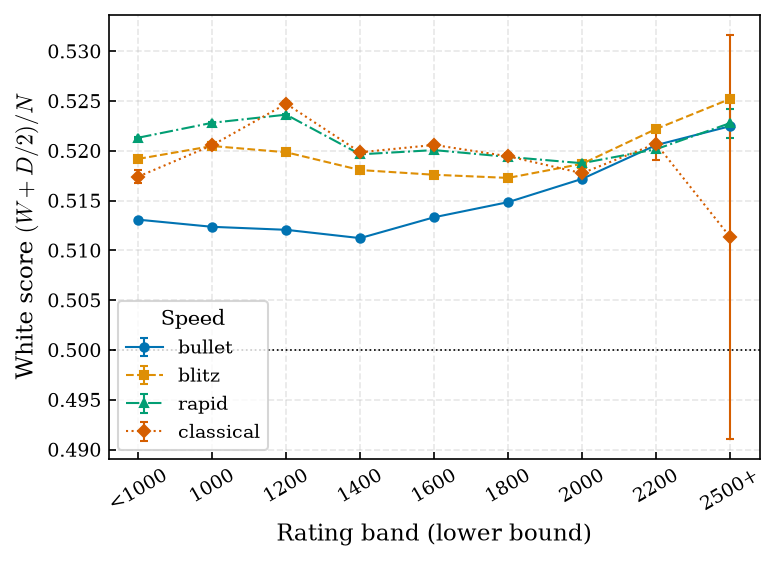

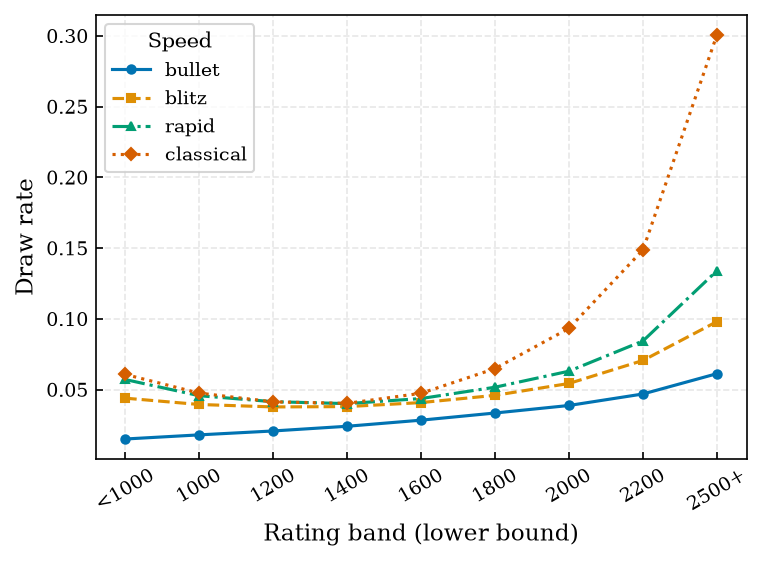

In [4]:
q1 = stats.q1_table(est)
display(q1.assign(N=q1.N.map("{:,.0f}".format)))
fig = plotting.plot_q1(q1)
fig = plotting.plot_draw_rate(q1)

In [5]:
# Pooled-over-bands view per speed (N-weighted), restricted to the analysis set
a = q1[q1.band >= MIN_BAND].copy()
a["w_pts"] = a.score * a.N
pooled = a.groupby("speed").apply(lambda d: pd.Series({
    "N": d.N.sum(), "score": d.w_pts.sum() / d.N.sum(),
    "score_min_band": d.score.min(), "score_max_band": d.score.max()}), include_groups=False)
pooled

,N,score,score_min_band,score_max_band
speed,,,,
blitz,3240425471.0000,0.5184,0.5173,0.5252
bullet,2469377670.0000,0.5145,0.5112,0.5225
classical,73056124.0000,0.5210,0.5114,0.5247
rapid,958105377.0000,0.5205,0.5188,0.5236


## 4. Q2: open vs. closed families
Families (fixed a priori): **open** 1.e4 e5; **semi-open** 1.e4 other; **closed** 1.d4 d5; **semi-closed** 1.d4 other; **flank** everything else. Ranges = min/max of the White score across rating bands in the analysis set, per speed.

In [6]:
ranges = stats.q2_ranges(est, min_band=MIN_BAND, min_n=MIN_N)
display(ranges.pivot(index="family", columns="speed", values=["min", "max"]).round(4))

min                            max                        
speed        blitz bullet classical  rapid  blitz bullet classical  rapid
family                                                                   
closed      0.5295 0.5323    0.5267 0.5276 0.5390 0.5399    0.5501 0.5402
flank       0.5147 0.5154    0.4807 0.5096 0.5320 0.5286    0.5432 0.5358
open        0.5187 0.5163    0.5173 0.5106 0.5314 0.5272    0.5423 0.5341
semi_closed 0.5141 0.5077    0.5116 0.5143 0.5238 0.5193    0.5318 0.5269
semi_open   0.5012 0.4927    0.4943 0.4997 0.5237 0.5171    0.5222 0.5192

In [7]:
# Contrasts between disjoint families (difference in White score with 95% CI)
contrasts = pd.concat({
    "open - closed":          stats.contrast(est, "open", "closed"),
    "open - semi_open":       stats.contrast(est, "open", "semi_open"),
    "closed - semi_closed":   stats.contrast(est, "closed", "semi_closed"),
}, names=["contrast"]).reset_index(level=0)
contrasts = contrasts[contrasts.band >= MIN_BAND]
display(contrasts.pivot_table(index=["contrast", "speed"], columns="band", values="diff").round(4))
display(contrasts.assign(sig=lambda d: (d.lo > 0) | (d.hi < 0)).groupby(["contrast", "speed"]).sig.mean().unstack())

band                              1200    1400    1600    1800    2000  \
contrast             speed                                               
closed - semi_closed blitz      0.0209  0.0228  0.0238  0.0247  0.0205   
                     bullet     0.0315  0.0298  0.0280  0.0266  0.0250   
                     classical -0.0051  0.0132  0.0311  0.0364  0.0315   
                     rapid      0.0117  0.0206  0.0248  0.0257  0.0247   
open - closed        blitz     -0.0083 -0.0077 -0.0064 -0.0098 -0.0155   
                     bullet    -0.0121 -0.0122 -0.0146 -0.0172 -0.0214   
                     classical  0.0102  0.0012 -0.0080 -0.0079 -0.0094   
                     rapid     -0.0023 -0.0069 -0.0064 -0.0059 -0.0097   
open - semi_open     blitz      0.0236  0.0286  0.0303  0.0261  0.0159   
                     bullet     0.0344  0.0338  0.0274  0.0198  0.0110   
                     classical  0.0146  0.0288  0.0448  0.0479  0.0346   
                     rapid      0.0196  0.0278  0.0341  0.0324  0.0247   

band                              2200    2500  
contrast             speed                      
closed - semi_closed blitz      0.0085  0.0062  
                     bullet     0.0203  0.0131  
                     classical  0.0189  0.0969  
                     rapid      0.0130  0.0007  
open - closed        blitz     -0.0136 -0.0082  
                     bullet    -0.0213 -0.0160  
                     classical -0.0165 -0.0662  
                     rapid     -0.0151 -0.0170  
open - semi_open     blitz      0.0034 -0.0025  
                     bullet     0.0034 -0.0008  
                     classical  0.0040 -0.0333  
                     rapid      0.0057 -0.0086

speed,blitz,bullet,classical,rapid
contrast,,,,
closed - semi_closed,1.0000,1.0000,1.0000,0.8571
open - closed,1.0000,1.0000,0.8571,1.0000
open - semi_open,1.0000,1.0000,0.7143,1.0000


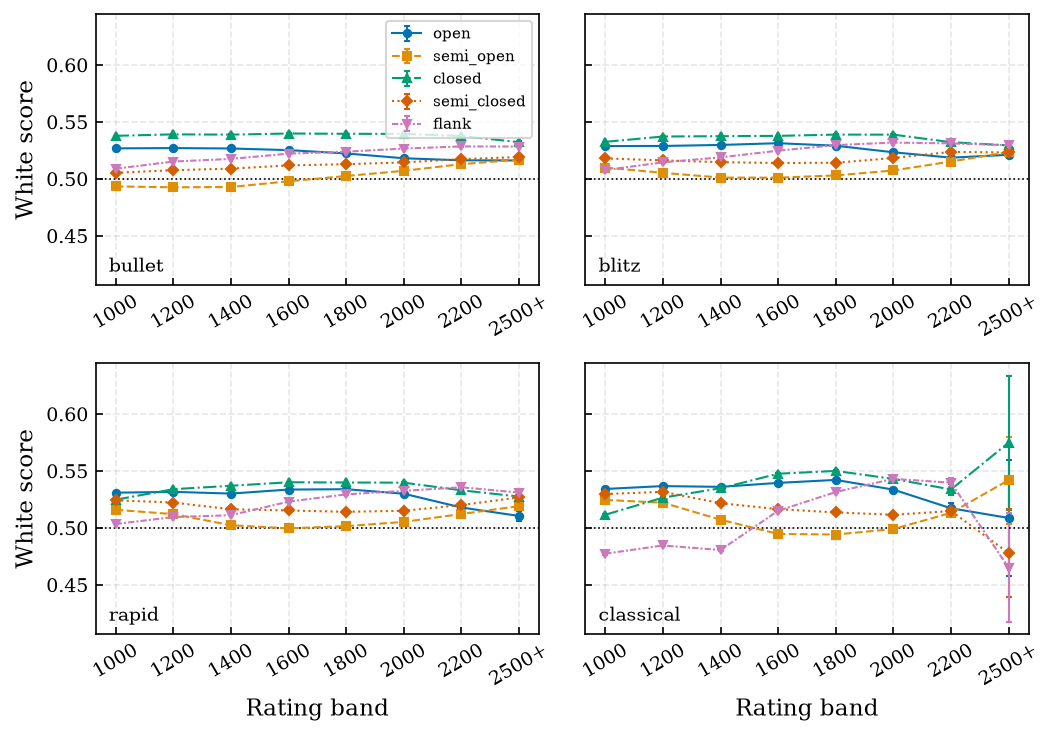

In [8]:
fig = plotting.plot_q2(est, stats.FAMILIES, min_band=1000)

## 5. Wikipedia scrape (taxonomy)
Source: *List of ECO codes* (columns Code / Moves / Main article). Each code is assigned a family from its **first two plies** (matching the explorer splits); if the moves cell is ambiguous (e.g. just `1.e4`) it falls back to the ECO-range map. The cross-tab validates that fallback: ECO-range vs. first-move families should agree almost everywhere.

In [9]:
wiki = wiki_scrape.load_openings()
print(len(wiki), "ECO codes scraped;", wiki.family_moves.notna().sum(), "classified from moves")
display(wiki.family.value_counts().rename("ECO codes").to_frame())

both = wiki.dropna(subset=["family_moves"])
print(f"ECO-range map agrees with first-move map on {(both.family_eco == both.family_moves).mean():.1%} of codes")
display(pd.crosstab(both.family_eco, both.family_moves))
wiki.head(10)

500 ECO codes scraped; 497 classified from moves


,ECO codes
family,
semi_closed,190
semi_open,120
open,80
closed,70
flank,40


ECO-range map agrees with first-move map on 100.0% of codes


family_moves,closed,flank,open,semi_closed,semi_open
family_eco,,,,,
closed,70,0,0,0,0
flank,0,39,0,0,0
open,0,0,80,0,0
semi_closed,0,0,0,189,0
semi_open,0,0,0,0,119


,eco,moves,article,family_eco,family_moves,family
0,A00,"Moves other than 1.e4, 1.d4, 1.Nf3, 1.c4, 1.b3...",Irregular openings,flank,NaN,flank
1,A01,1.b3,Nimzowitsch–Larsen Attack,flank,flank,flank
2,A02,1.f4,Bird Opening,flank,flank,flank
3,A03,1.f4 d5,NaN,flank,flank,flank
4,A04,1.Nf3,Zukertort Opening,flank,flank,flank
5,A05,1.Nf3 Nf6,NaN,flank,flank,flank
6,A06,1.Nf3 d5,NaN,flank,flank,flank
7,A07,1.Nf3 d5 2.g3,NaN,flank,flank,flank
8,A08,1.Nf3 d5 2.g3 c5 3.Bg2 / 1.Nf3 d5 2.g3 c5,NaN,flank,flank,flank
9,A09,1.Nf3 d5 2.c4,Réti Opening,flank,flank,flank


## 6. Threats to validity
- **Selection / endogeneity.** Black chooses the defense and strong players self-select into lines, so family differences are partly selection, not intrinsic opening strength. The contrasts are descriptive, not causal.
- **Rating buckets.** Verify in the current API docs whether buckets use per-player or average game rating; interpretation of "band" depends on it.
- **Low bands.** Provisional ratings and blunder-driven results; hence `MIN_BAND`. Raw bottom bands are kept in the data but excluded from Q2 ranges.
- **Speed is a first-order moderator.** Never pool bullet with classical. Pooled numbers above are within speed only.
- **Family map is approximate.** ECO is structural; the explorer-derived families are first-move based.
- **Multiple dependent cells.** Bands/speeds are not independent tests; CIs are per-cell, not simultaneous.

In [10]:
# Export LaTeX (booktabs) tables for the paper
os.makedirs("figures", exist_ok=True)
t1 = q1[["speed", "band", "N", "score", "lo", "hi", "draw_rate"]].copy()
t1["band"] = t1.band.map(plotting.band_label)
t1.to_latex("figures/table_q1.tex", index=False, float_format="%.4f", longtable=False)
ranges.to_latex("figures/table_q2_ranges.tex", index=False, float_format="%.4f")
print("wrote figures/table_q1.tex, figures/table_q2_ranges.tex")

wrote figures/table_q1.tex, figures/table_q2_ranges.tex
